#  Molecule Ideation Assistant
### Powered by NVIDIA BioNeMo (MolMIM) + Muse Glimmer (NVIDIA NIM)

**Domain:** Drug Discovery | **AI Approach:** Generative AI + LLM Reasoning

---
This project builds an AI-powered pipeline that takes a real FDA-approved drug (lead compound)
and generates optimised analog candidates under three simultaneous constraints:
-  **Drug-likeness** — QED score
-  **Toxicity** — LogP, Lipinski rules, PAINS, reactive-group alerts, hERG-risk heuristic
-  **Synthesis feasibility** — SA score (synthetic accessibility, 1 = easy, 10 = hard)

**Reduces analog ideation from weeks of manual effort to under 5 minutes.**

##  Step 1: Install Dependencies
Installing RDKit for molecular validation and OpenAI client for NVIDIA NIM API access.

In [ ]:

!pip install rdkit pandas requests python-dotenv openai streamlit chembl-webresource-client -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 59.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 3.7 MB/s eta 0:00:00


## 🔑 Step 2: Load API Keys
- **NVIDIA_API_KEY** — for NVIDIA BioNeMo (MolMIM molecule generation)
- **LLM_API_KEY** — for Muse Glimmer via NVIDIA NIM (reasoning + ranking). Falls back to LLAMA_API_KEY, then NVIDIA_API_KEY.

Keys are stored securely in Colab Secrets (not hardcoded).

In [ ]:
from google.colab import userdata

# Check exact secret names available
import json

# Try these variations
try:
    k1 = userdata.get('LLM_API_KEY')
    print("LLM_API_KEY works:", "loaded")
except:
    print("LLM_API_KEY - NOT FOUND")

try:
    k2 = userdata.get('NVIDIA_API_KEY')
    print("NVIDIA_API_KEY works:", "loaded")
except:
    print("NVIDIA_API_KEY - NOT FOUND")

LLM_API_KEY works: loaded
NVIDIA_API_KEY works: loaded


##  Step 3: Full Pipeline
Three-stage pipeline:

| Stage | Tool | Role |
|-------|------|------|
| 1. Generate | NVIDIA BioNeMo MolMIM | Generate 10 analog candidates from lead SMILES |
| 2. Validate | RDKit | QED scoring, LogP, Lipinski rules, PAINS filtering, hERG-risk heuristic, reactive-group alerts, SA score |
| 3. Rank | Muse Glimmer (NIM) | Rank top 3 with plain-English medicinal chemistry rationale |

In [ ]:
import requests
import os
from google.colab import userdata

def get_key(*names):
    """Return the first Colab secret found (whitespace stripped)."""
    for name in names:
        try:
            val = userdata.get(name)
            if val:
                return val.strip()
        except Exception:
            continue
    raise KeyError(f"None of these Colab secrets were found: {names}")

llm_api_key = get_key('LLM_API_KEY', 'LLAMA_API_KEY', 'NVIDIA_API_KEY')   # key for the LLM (Muse Glimmer)
nvidia_api_key = get_key('NVIDIA_API_KEY')                    # key for MolMIM

LLM_URL = "https://integrate.api.nvidia.com/v1/chat/completions"
MODELS_URL = "https://integrate.api.nvidia.com/v1/models"
LLM_MODEL = "meta/muse-glimmer-30b"   # copy the exact id from the model page if this differs

def find_llm_model(preferred):
    try:
        r = requests.get(MODELS_URL, headers={"Authorization": f"Bearer {llm_api_key}"}, timeout=30)
        ids = [m["id"] for m in r.json().get("data", [])]
        if preferred in ids:
            return preferred
        matches = [i for i in ids if "glimmer" in i.lower()]
        if matches:
            print("Using model id from catalog:", matches[0])
            return matches[0]
        print("No Muse Glimmer id found in /v1/models. Keeping:", preferred)
    except Exception as e:
        print("Could not list models:", e)
    return preferred

LLM_MODEL = find_llm_model(LLM_MODEL)

# Test LLM key on the Muse Glimmer endpoint
headers = {
    "Authorization": f"Bearer {llm_api_key}",
    "Content-Type": "application/json"
}
payload = {
    "model": LLM_MODEL,
    "messages": [{"role": "user", "content": "say hello"}],
    "max_tokens": 50
}
response = requests.post(LLM_URL, headers=headers, json=payload)
print("LLM key on Muse Glimmer endpoint:", response.status_code, "| model:", LLM_MODEL)

# Test NVIDIA key on MolMIM endpoint
headers2 = {
    "Authorization": f"Bearer {nvidia_api_key}",
    "Content-Type": "application/json"
}
payload2 = {
    "smi": "CC(=O)Oc1ccccc1C(=O)O",
    "num_molecules": 3,
    "property_name": "QED",
    "minimize": False,
    "min_similarity": 0.3,
    "particles": 30,
    "iterations": 10
}
url2 = "https://health.api.nvidia.com/v1/biology/nvidia/molmim/generate"
response2 = requests.post(url2, headers=headers2, json=payload2)
print("NVIDIA key on MolMIM endpoint:", response2.status_code)

if response.status_code == 200 and response2.status_code == 200:
    print("Both APIs working. Continue.")
else:
    print("Fix the failing key first (401/403 = wrong key, 404 = wrong model id, 429 = rate limit).")
    if response.status_code != 200:
        print("LLM response:", response.text[:300])
    if response2.status_code != 200:
        print("MolMIM response:", response2.text[:300])


LLM key on Muse Glimmer endpoint: 200 | model: meta/muse-glimmer-30b
NVIDIA key on MolMIM endpoint: 200
Both APIs working. Continue.


##  Step 3b: SA score + hERG-risk heuristic helpers (new)
- **SA score** (RDKit Contrib): 1 = easy to make, 10 = hard. Buckets: < 4 Easy, < 6 Moderate, otherwise Complex.
- **hERG-risk heuristic**: one point each for a basic aliphatic amine, logP >= 3.5, and >= 2 aromatic rings. 0-1 = LOW, 2 = MODERATE, 3 = HIGH. This is a screening rule of thumb, not a hERG prediction model.

In [28]:
import sys, os, requests
from rdkit import Chem
from rdkit.Chem import RDConfig, rdMolDescriptors, Descriptors

def load_sascorer():
    try:
        sa_dir = os.path.join(RDConfig.RDContribDir, "SA_Score")
        if os.path.exists(os.path.join(sa_dir, "sascorer.py")):
            sys.path.append(sa_dir)
            import sascorer
            return sascorer
    except Exception:
        pass
    os.makedirs("sa_score", exist_ok=True)
    base = "https://raw.githubusercontent.com/rdkit/rdkit/master/Contrib/SA_Score/"
    for fname in ["sascorer.py", "fpscores.pkl.gz"]:
        path = os.path.join("sa_score", fname)
        if not os.path.exists(path):
            resp = requests.get(base + fname, timeout=60)
            resp.raise_for_status()
            with open(path, "wb") as f:
                f.write(resp.content)
    sys.path.append("sa_score")
    import sascorer
    return sascorer

sascorer = load_sascorer()
print("SA score for aspirin (expect ~1.5-2):", round(sascorer.calculateScore(Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")), 2))

# Basic aliphatic amine: not an aniline, amide/thioamide/amidine, sulfonamide, N-N/N-O, or nitrile-N
BASIC_AMINE = Chem.MolFromSmarts(
    "[NX3;!$(N-a);!$(N-[#6,#16]=[O,S,N]);!$(N-S(=O)=O);!$(N-[#7,#8]);!$(N-C#N)]"
)

def herg_risk_heuristic(mol):
    """Returns (level, has_basic_amine, n_aromatic_rings). Heuristic only, not a hERG model."""
    logp = Descriptors.MolLogP(mol)
    n_arom = rdMolDescriptors.CalcNumAromaticRings(mol)
    basic_n = mol.HasSubstructMatch(BASIC_AMINE)
    points = int(basic_n) + int(logp >= 3.5) + int(n_arom >= 2)
    level = "LOW" if points <= 1 else ("MODERATE" if points == 2 else "HIGH")
    return level, basic_n, n_arom

print("hERG-risk heuristic on aspirin:", herg_risk_heuristic(Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")))


SA score for aspirin (expect ~1.5-2): 1.58
hERG-risk heuristic on aspirin: ('LOW', False, 1)


##  Step 4: Pipeline Functions + Initial Test (Aspirin)
Defining all three pipeline functions and running an initial test on Aspirin as the lead compound.

In [29]:
import requests
import os
import json
from rdkit import Chem
from rdkit.Chem import Descriptors, QED
from google.colab import userdata

# Retrieve API keys from Colab's user data and set them as environment variables
os.environ['NVIDIA_API_KEY'] = get_key('NVIDIA_API_KEY')
os.environ['LLAMA_API_KEY'] = get_key('LLM_API_KEY', 'LLAMA_API_KEY', 'NVIDIA_API_KEY')

# ============================================
# STEP 1: GENERATE ANALOGS VIA MOLMIM
# ============================================
def generate_analogs(smiles, num_samples=10):
    url = "https://health.api.nvidia.com/v1/biology/nvidia/molmim/generate"
    headers = {
        "Authorization": f"Bearer {os.environ['NVIDIA_API_KEY']}",
        "Content-Type": "application/json"
    }
    payload = {
        "smi": smiles,
        "num_molecules": num_samples,
        "property_name": "QED",
        "minimize": False,
        "min_similarity": 0.3,
        "particles": 30,
        "iterations": 10
    }
    response = requests.post(url, headers=headers, json=payload)
    if response.status_code == 200:
        return response.json()
    else:
        print("MolMIM Error:", response.status_code, response.text)
        return None
        #DE-DUPLICATE
def dedupe_smiles(smiles_list):
    """Drop invalid and duplicate molecules (compared by canonical SMILES), keeping order."""
    seen, unique = set(), []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        can = Chem.MolToSmiles(mol)
        if can in seen:
            continue
        seen.add(can)
        unique.append(smi)
    n_removed = len(smiles_list) - len(unique)
    if n_removed:
        print(f"   removed {n_removed} duplicate/invalid analog(s)")
    return unique
# ============================================
# STEP 2: VALIDATE + SCORE VIA RDKIT
# ============================================
def validate_and_score(smiles_list):
    smiles_list = dedupe_smiles(smiles_list)
    results = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        mw = Descriptors.MolWt(mol)
        logp = Descriptors.MolLogP(mol)
        hbd = Descriptors.NumHDonors(mol)
        hba = Descriptors.NumHAcceptors(mol)
        qed = QED.qed(mol)

        # Lipinski rule of 5
        lipinski = mw <= 500 and logp <= 5 and hbd <= 5 and hba <= 10

        # Simple toxicity flag based on logP
        if logp > 5:
            tox_flag = "⚠️ WARN - High lipophilicity"
        elif logp < 0:
            tox_flag = "⚠️ WARN - Too hydrophilic"
        else:
            tox_flag = "✅ PASS"

        # Synthesis score (real SA score: 1 = easy, 10 = hard)
        sa_score = sascorer.calculateScore(mol)
        synth_score = "✅ Easy" if sa_score < 4 else "⚠️ Moderate" if sa_score < 6 else "❌ Complex"

        results.append({
            "smiles": smi,
            "mol_weight": round(mw, 2),
            "logP": round(logp, 2),
            "QED": round(qed, 3),
            "lipinski": "✅ PASS" if lipinski else "❌ FAIL",
            "toxicity": tox_flag,
            "synthesis": synth_score,
            "SA_score": round(sa_score, 2)
        })
    return results

# ============================================
# STEP 3: RANK + EXPLAIN VIA MUSE GLIMMER
# ============================================
def rank_with_llm(lead_smiles, candidates):
    url = "https://integrate.api.nvidia.com/v1/chat/completions"
    headers = {
        "Authorization": f"Bearer {os.environ['LLAMA_API_KEY']}",
        "Content-Type": "application/json"
    }

    candidate_text = "\n".join([
        f"{i+1}. SMILES: {c['smiles']} | MW: {c['mol_weight']} | LogP: {c['logP']} | QED: {c['QED']} | Lipinski: {c['lipinski']} | Toxicity: {c['toxicity']} | Synthesis: {c['synthesis']} (SA score {c['SA_score']})"
        for i, c in enumerate(candidates)
    ])

    prompt = f"""You are an expert medicinal chemist AI assistant.\n\nLead compound SMILES: {lead_smiles}\n\nThe following analog candidates were generated. Rank the TOP 3 and explain why each is a good drug candidate based on drug-likeness (QED score), toxicity (LogP, toxicity flag), and synthesis feasibility (SA score).\n\nCandidates:\n{candidate_text}\n\nFor each of your top 3, provide:\n- Rank and SMILES\n- Why it's promising (drug-likeness, safety, synthesisability)\n- Any concerns\n\nBe concise and clear."""

    payload = {
        "model": LLM_MODEL,
        "messages": [{"role": "user", "content": prompt}],
        "max_tokens": 6000,
        "temperature": 0.3
    }

    response = requests.post(url, headers=headers, json=payload)
    if response.status_code == 200:
        data = response.json()
        choice = data["choices"][0]
        if choice.get("finish_reason") == "length":
            print("WARNING: LLM reply was CUT OFF (finish_reason=length, completion_tokens =",
                  data.get("usage", {}).get("completion_tokens"), "). Raise max_tokens.")
        return choice["message"]["content"]
    else:
        print("Llm Error:", response.status_code, response.text)
        return None

# ============================================
# RUN THE FULL PIPELINE
# ============================================
lead = "CC(=O)Oc1ccccc1C(=O)O"  # Aspirin
print("=" * 50)
print(f"Lead Compound: {lead}")
print("=" * 50)

print("\n Step 1: Generating analogs via MolMIM...")
result = generate_analogs(lead, num_samples=10)
# Parse the 'molecules' string into a Python list and extract 'sample' (SMILES)
smiles_list = [item["sample"] for item in json.loads(result["molecules"])]
print(f" {len(smiles_list)} analogs generated")

print("\n Step 2: Validating via RDKit...")
scored = validate_and_score(smiles_list)
print(f" {len(scored)} valid candidates scored")

print("\n Step 3: Ranking via Muse Glimmer...")
explanation = rank_with_llm(lead, scored)
print("\n" + "=" * 50)
print("FINAL RANKED OUTPUT:")
print("=" * 50)
print(explanation)


Lead Compound: CC(=O)Oc1ccccc1C(=O)O

 Step 1: Generating analogs via MolMIM...
 10 analogs generated

 Step 2: Validating via RDKit...
   removed 3 duplicate/invalid analog(s)
 7 valid candidates scored

 Step 3: Ranking via Muse Glimmer...

FINAL RANKED OUTPUT:
**Lead = Aspirin CC(=O)Oc1ccccc1C(=O)O. All analogs keep Lipinski PASS and Toxicity PASS.**

### 1. Rank 1 - Candidate 1
**SMILES:** `O=C(O)c1ccccc1OCc1ccccc1Br`
MW 307.14 | LogP 3.73 | QED 0.936 | SA 1.65 Easy

* Why promising: Highest QED of the set 0.936 = excellent drug-likeness. Benzoic acid is retained for the lead pharmacophore. LogP 3.73 is within the desirable <5 range and gives reasonable membrane permeability without excessive lipophilicity. SA 1.65 = easy, benzyl ether formation is straightforward.
* Concerns: Bromobenzyl ether. Aryl bromide is a potential metabolic liability / clearance issue and can raise hERG / reactive metabolite risk despite the PASS flag. MW ~307 is the highest of the top set, solubility may 

### Helper Function: rank_with_llm_v2
Upgraded ranking function that includes PAINS, hERG, and structural alert data in the LLM prompt.

In [30]:
def rank_with_llm_v2(lead_smiles, candidates):
    url = "https://integrate.api.nvidia.com/v1/chat/completions"
    headers = {
        "Authorization": f"Bearer {os.environ['LLAMA_API_KEY']}",
        "Content-Type": "application/json"
    }
    candidate_text = "\n".join([
        f"{i+1}. SMILES: {c['smiles']} | QED: {c['QED']} | LogP: {c['logP']} | "
        f"Lipinski: {c['lipinski']} | PAINS: {c['PAINS']} | "
        f"hERG: {c['hERG']} | Alerts: {c['structural_alerts']} | "
        f"Tox Overall: {c['tox_overall']} | Synthesis: {c['synthesis']} (SA score {c['SA_score']}) | "
        f"Est. potency: {c.get('potency_text', 'n/a')})"
        for i, c in enumerate(candidates)
    ])
    prompt = f"""You are an expert medicinal chemist AI assistant.

Lead compound SMILES: {lead_smiles}

Analog candidates with full scoring including PAINS toxicity screening:
{candidate_text}

Rank the TOP 3 analogs considering:
1. Drug-likeness — QED score (higher is better)
2. Safety — PAINS filter, hERG risk, structural alerts (all should PASS)
3. Synthesis — SA score (lower is easier)
4. Potency — estimated pChEMBL vs the lead (higher is better; do not rely on estimates marked LOW confidence)
For each top 3 provide:
- Rank and SMILES
- Why it's promising
- Any concerns

Be concise and scientific."""

    payload = {
        "model": LLM_MODEL,
        "messages": [{"role": "user", "content": prompt}],
        "max_tokens": 6000,
        "temperature": 0.3
    }
    response = requests.post(url, headers=headers, json=payload)
    if response.status_code == 200:
        data = response.json()
        choice = data["choices"][0]
        if choice.get("finish_reason") == "length":
            print("WARNING: LLM reply was CUT OFF (finish_reason=length, completion_tokens =",
                  data.get("usage", {}).get("completion_tokens"), "). Raise max_tokens.")
        return choice["message"]["content"]
    else:
        print("Llama Error:", response.status_code)
        return None

print(" rank_with_llm_v2 loaded")

 rank_with_llm_v2 loaded


##  Step 5: Display Results — Aspirin Test

In [31]:
import pandas as pd

# ============================================
# DISPLAY CLEAN OUTPUT TABLE
# ============================================
print("\n" + "=" * 60)
print("       MOLECULE IDEATION ASSISTANT — RESULTS")
print("       Powered by NVIDIA BioNeMo + Muse Glimmer")
print("=" * 60)
print(f"\n Lead Compound (Aspirin): {lead}\n")

# Build display dataframe
df = pd.DataFrame(scored)
df.index = df.index + 1  # start from 1

print(" ALL CANDIDATES SCORED:\n")
print(df[["smiles", "mol_weight", "logP", "QED",
          "lipinski", "toxicity", "synthesis", "SA_score"]].to_string())

print("\n" + "=" * 60)
print(" MUSE GLIMMER TOP 3 RECOMMENDATIONS:")
print("=" * 60)
print(explanation)

print("\n" + "=" * 60)
print(" Pipeline complete — NVIDIA BioNeMo + RDKit + Muse Glimmer")
print(f"   {len(smiles_list)} analogs generated → {len(scored)} validated → Top 3 ranked")
print("=" * 60)


       MOLECULE IDEATION ASSISTANT — RESULTS
       Powered by NVIDIA BioNeMo + Muse Glimmer

 Lead Compound (Aspirin): CC(=O)Oc1ccccc1C(=O)O

 ALL CANDIDATES SCORED:

                              smiles  mol_weight  logP    QED lipinski toxicity synthesis  SA_score
1         O=C(O)c1ccccc1OCc1ccccc1Br      307.14  3.73  0.936   ✅ PASS   ✅ PASS    ✅ Easy      1.65
2          O=C(O)c1ccccc1Oc1ccccc1Br      293.12  3.94  0.932   ✅ PASS   ✅ PASS    ✅ Easy      1.66
3       O=C(O)c1ccccc1COc1cccc(Cl)c1      262.69  3.62  0.915   ✅ PASS   ✅ PASS    ✅ Easy      1.60
4         O=C(O)c1ccccc1COc1ccccc1Cl      262.69  3.62  0.915   ✅ PASS   ✅ PASS    ✅ Easy      1.57
5          NC(=O)c1ccccc1Oc1ccccc1Cl      247.68  3.23  0.905   ✅ PASS   ✅ PASS    ✅ Easy      1.60
6  O=C(O)c1ccccc1Oc1cccc(Cl)c1C(=O)O      292.67  3.53  0.900   ✅ PASS   ✅ PASS    ✅ Easy      1.86
7          O=C(O)c1ccccc1Oc1ccccc1Cl      248.66  3.83  0.898   ✅ PASS   ✅ PASS    ✅ Easy      1.55

 MUSE GLIMMER TOP 3 RECOMMENDA

##  Step 5b: Molecule Visualizations
Displaying 2D structure of lead compound and top 3 analog candidates using RDKit.

In [32]:
from rdkit import Chem
from rdkit.Chem import Draw, AllChem

def visualize_molecules(lead_smiles, scored_candidates, top_n=3):
    top = sorted(scored_candidates, key=lambda x: x['QED'], reverse=True)[:top_n]

    mols = []
    labels = []

    def _process_mol_for_viz(smi, label_prefix=""):
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            print(f"Warning: Could not create molecule from SMILES: '{smi}'")
            return None, None

        try:
            # Ensure kekulization, sanitization, and 2D coord generation for robust depiction
            Chem.Kekulize(mol) # Explicitly kekulize for better aromatic representation
            Chem.SanitizeMol(mol)
            AllChem.Compute2DCoords(mol)
            return mol, label_prefix
        except Exception as e:
            print(f"Warning: Could not fully process SMILES '{smi}' for visualization: {e}")
            # Fallback: if sanitization/2D coord fails, try to just add the parsed mol if it exists
            if mol:
                return mol, f"{label_prefix} (RENDER ISSUE)"
            return None, None

    # Process lead compound
    processed_lead_mol, processed_lead_label = _process_mol_for_viz(lead_smiles, "LEAD COMPOUND")
    if processed_lead_mol:
        mols.append(processed_lead_mol)
        labels.append(processed_lead_label)

    # Process analog candidates
    for i, candidate in enumerate(top):
        smi = candidate['smiles']
        # Extract toxicity status and remove emojis for better display
        display_tox_status = candidate.get('tox_overall', candidate.get('toxicity', 'N/A'))
        if '✅' in display_tox_status:
            display_tox_status = 'PASS'
        elif '⚠️' in display_tox_status:
            display_tox_status = 'WARN'
        elif '❌' in display_tox_status:
            display_tox_status = 'Invalid'

        analog_label_prefix = (
            f"Rank {i+1} | QED: {candidate['QED']:.3f} | "
            f"LogP: {candidate['logP']:.2f} | "
            f"Tox: {display_tox_status}"
        )
        processed_analog_mol, processed_analog_label = _process_mol_for_viz(smi, analog_label_prefix)

        if processed_analog_mol:
            mols.append(processed_analog_mol)
            labels.append(processed_analog_label)

    if not mols:
        print("Error: No valid molecules to display.")
        return

    img = Draw.MolsToGridImage(
        mols,
        molsPerRow=2,
        subImgSize=(500, 450),
        legends=labels
    )

    display(img)
    print(f" Lead compound + top {len(mols) - 1 if mols else 0} analogs by QED score")

   2D MOLECULE STRUCTURES — ASPIRIN ANALOGS


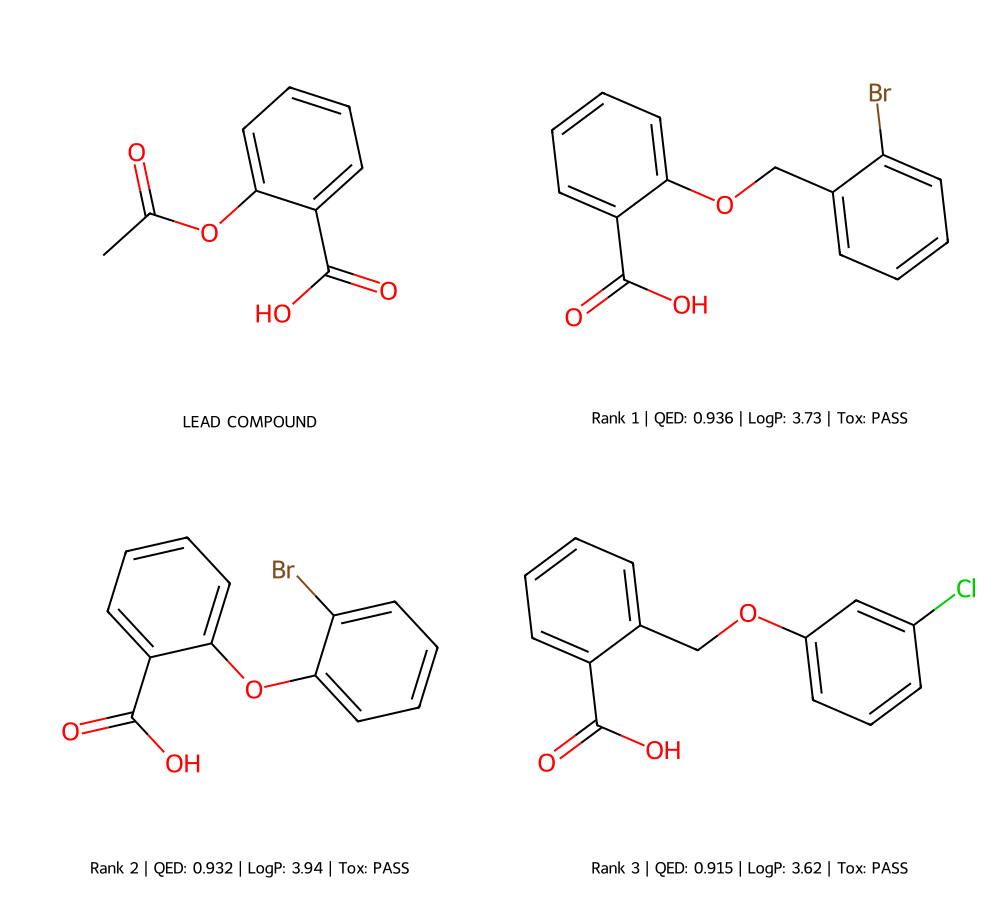

 Lead compound + top 3 analogs by QED score


In [33]:
# Run visualization
print("=" * 60)
print("   2D MOLECULE STRUCTURES — ASPIRIN ANALOGS")
print("=" * 60)
visualize_molecules(lead, scored)

##  Step 6: Real FDA-Approved Lead Compounds (ChEMBL)
Testing on real drugs makes this clinically relevant.
Selected **Imatinib (Gleevec)** — a breakthrough cancer drug — as our lead compound.

In [34]:
import json
import requests
import os
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

# ============================================
# REAL DRUG LEADS FROM CHEMBL
# ============================================
drugs = {
    "Imatinib (Gleevec - Cancer)":     "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1",
    "Gefitinib (Lung Cancer)":          "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1",
    "Oseltamivir (Tamiflu - Flu)":      "CCOC(=O)C1=C[C@@H](OC(CC)CC)[C@@H](NC(C)=O)[C@@H](N)C1",
    "Metformin (Diabetes)":             "CN(C)C(=N)NC(N)=N",
    "Ciprofloxacin (Antibiotic)":       "O=C(O)c1cn(C2CC2)c2cc(N3CCNCC3)c(F)cc2c1=O"
}
print("=" * 60)
print("   AVAILABLE LEAD COMPOUNDS (Real FDA-approved drugs)")
print("=" * 60)
for i, (name, smi) in enumerate(drugs.items()):
    print(f"\n{i+1}. {name}")
    print(f"   SMILES: {smi[:50]}...")

print("\n" + "=" * 60)

# ============================================
# RDKit PAINS Toxicity Screening
# ============================================
def check_toxicity_pains(smiles):
    """
    Real toxicity screening using RDKit PAINS + structural alerts
    PAINS = Pan-Assay Interference Compounds
    Used in real pharmaceutical research to flag problematic molecules
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return {"PAINS": "❌ Invalid", "hERG proxy": "❌ Invalid", "Structural alerts": "❌ Invalid", "overall": "❌ Invalid"}

    # PAINS filter — flags compounds that interfere with biological assays
    params = FilterCatalogParams()
    params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
    catalog = FilterCatalog(params)
    pains_hit = catalog.HasMatch(mol)

    # Structural alert checks via RDKit
    # hERG-risk heuristic: basic aliphatic amine + lipophilicity + aromatic rings (not a hERG model)
    herg_level, _, _ = herg_risk_heuristic(mol)
    herg_risk = (herg_level == "HIGH")

    # Reactive group alert — flags potentially toxic functional groups
    reactive_smarts = [
        "[N;!$(NC=O)][OH]",        # hydroxylamine
        "C(=O)[F,Cl,Br,I]",        # acid halide
        "[CH2][Cl,Br,I]",          # alkyl halide
        "N=[N+]=[N-]",             # azide
        "C1CO1",                   # epoxide
    ]
    reactive_flag = False
    for smarts in reactive_smarts:
        pattern = Chem.MolFromSmarts(smarts)
        if pattern and mol.HasSubstructMatch(pattern):
            reactive_flag = True
            break

    pains_flag =    "⚠️ PAINS alert"    if pains_hit    else "✅ No PAINS"
    herg_flag =     "⚠️ hERG-risk HIGH (heuristic)" if herg_risk else f"✅ hERG-risk {herg_level} (heuristic)"
    reactive =      "⚠️ Reactive group" if reactive_flag else "✅ No alerts"

    overall = "⚠️ WARN" if any([pains_hit, herg_risk, reactive_flag]) else "✅ PASS"

    return {
        "PAINS":             pains_flag,
        "hERG proxy":        herg_flag,
        "Structural alerts": reactive,
        "overall":           overall
    }

# ============================================
# UPGRADED FULL PIPELINE WITH PAINS TOXICITY
# ============================================
def rank_with_llm_v2(lead_smiles, candidates):
    url = "https://integrate.api.nvidia.com/v1/chat/completions"
    headers = {
        "Authorization": f"Bearer {os.environ['LLAMA_API_KEY']}",
        "Content-Type": "application/json"
    }
    candidate_text = "\n".join([
        f"{i+1}. SMILES: {c['smiles']} | QED: {c['QED']} | LogP: {c['logP']} | "
        f"Lipinski: {c['lipinski']} | PAINS: {c['PAINS']} | "
        f"hERG: {c['hERG']} | Alerts: {c['structural_alerts']} | "
        f"Tox Overall: {c['tox_overall']} | Synthesis: {c['synthesis']} (SA score {c['SA_score']})"
        for i, c in enumerate(candidates)
    ])

    prompt = f"""You are an expert medicinal chemist AI assistant.\n\nLead compound SMILES: {lead_smiles}\n\nAnalog candidates with full scoring including PAINS toxicity screening:\n{candidate_text}\n\nRank the TOP 3 analogs considering:\n1. Drug-likeness — QED score (higher is better)\n2. Safety — PAINS filter, hERG risk, structural alerts (all should PASS)\n3. Synthesis — SA score (lower is easier)\n\nFor each top 3 provide:\n- Rank and SMILES\n- Why it's promising\n- Any concerns\n\nBe concise and scientific."""

    payload = {
        "model": LLM_MODEL,
        "messages": [{"role": "user", "content": prompt}],
        "max_tokens": 6000,
        "temperature": 0.3
    }
    response = requests.post(url, headers=headers, json=payload)
    if response.status_code == 200:
        data = response.json()
        choice = data["choices"][0]
        if choice.get("finish_reason") == "length":
            print("WARNING: LLM reply was CUT OFF (finish_reason=length, completion_tokens =",
                  data.get("usage", {}).get("completion_tokens"), "). Raise max_tokens.")
        return choice["message"]["content"]
    else:
        print("Llm Error:", response.status_code)
        return None


# Run full pipeline on Imatinib
lead = drugs["Imatinib (Gleevec - Cancer)"]
print(f"\n Selected Lead: Imatinib (Gleevec)")
print(f"   SMILES: {lead}\n")

print(" Step 1: Generating analogs via MolMIM...")
result = generate_analogs(lead, num_samples=10)
smiles_list = [item["sample"] for item in json.loads(result["molecules"])]
print(f" {len(smiles_list)} analogs generated")

print("\n Step 2: Validating via RDKit + PAINS...")
scored = validate_and_score(smiles_list)
for candidate in scored:
    tox = check_toxicity_pains(candidate['smiles'])
    candidate['PAINS']             = tox['PAINS']
    candidate['hERG']              = tox['hERG proxy']
    candidate['structural_alerts'] = tox['Structural alerts'] # Corrected key name
    candidate['tox_overall']       = tox['overall']
print(f" {len(scored)} candidates scored + toxicity checked")

print("\n Step 3: Ranking via Muse Glimmer...")
explanation = rank_with_llm_v2(lead, scored)
print("\n" + "=" * 60)
print("   FINAL RANKED OUTPUT — IMATINIB ANALOGS")
print("=" * 60)
print(explanation)


   AVAILABLE LEAD COMPOUNDS (Real FDA-approved drugs)

1. Imatinib (Gleevec - Cancer)
   SMILES: Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2...

2. Gefitinib (Lung Cancer)
   SMILES: COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1...

3. Oseltamivir (Tamiflu - Flu)
   SMILES: CCOC(=O)C1=C[C@@H](OC(CC)CC)[C@@H](NC(C)=O)[C@@H](...

4. Metformin (Diabetes)
   SMILES: CN(C)C(=N)NC(N)=N...

5. Ciprofloxacin (Antibiotic)
   SMILES: O=C(O)c1cn(C2CC2)c2cc(N3CCNCC3)c(F)cc2c1=O...


 Selected Lead: Imatinib (Gleevec)
   SMILES: Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1

 Step 1: Generating analogs via MolMIM...
 10 analogs generated

 Step 2: Validating via RDKit + PAINS...
   removed 4 duplicate/invalid analog(s)
 6 candidates scored + toxicity checked

 Step 3: Ranking via Muse Glimmer...

   FINAL RANKED OUTPUT — IMATINIB ANALOGS
**Top 3 ranked by QED > Safety PASS > SA low**

### 1. Rank 1
**SMILES:** `Cc1ccc(C)c(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)c1`
* QED 0.93 | LogP 3.3 

   2D MOLECULE STRUCTURES — IMATINIB ANALOGS


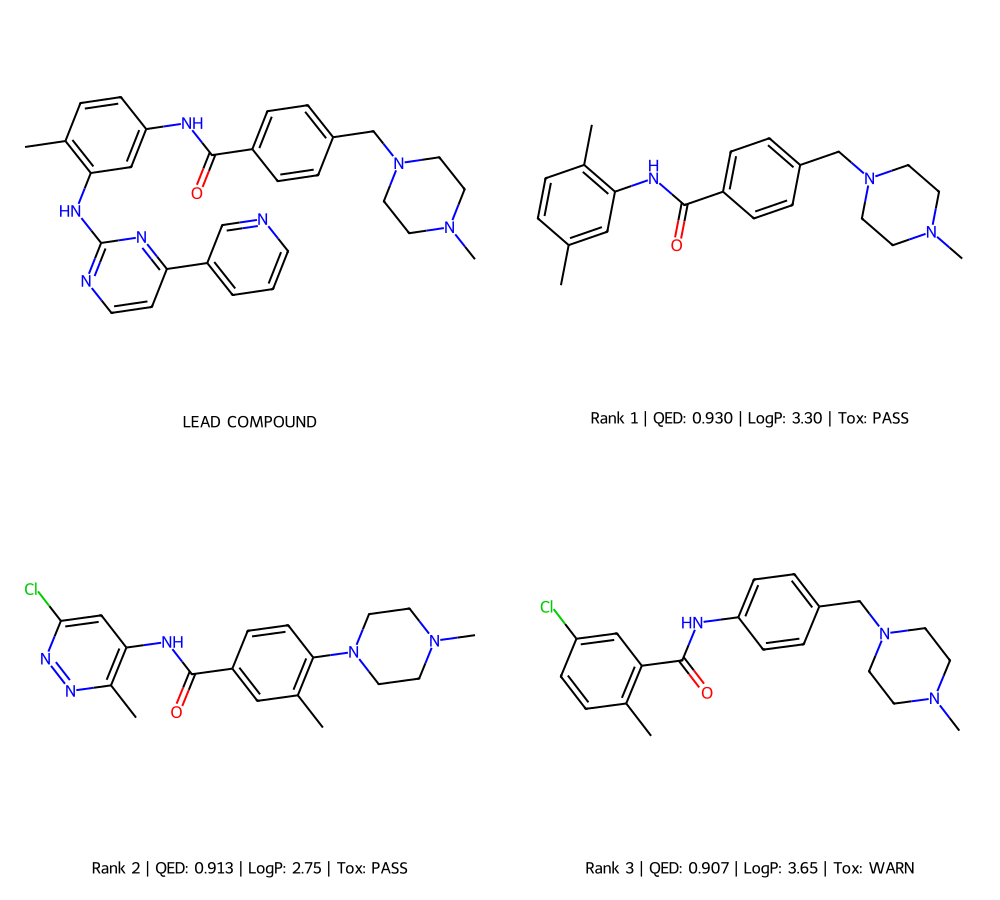

 Lead compound + top 3 analogs by QED score


In [35]:
print("=" * 60)
print("   2D MOLECULE STRUCTURES — IMATINIB ANALOGS")
print("=" * 60)
visualize_molecules(lead, scored)

## Step 7: Real ChEMBL API Integration
Fetching real FDA-approved lead compounds programmatically from ChEMBL database instead of hardcoded dictionary.

In [36]:
from chembl_webresource_client.new_client import new_client

def fetch_chembl_leads(max_molecules=5):
    molecule = new_client.molecule
    approved = molecule.filter(
        max_phase=4,
        molecule_type="Small molecule"
    ).only(['molecule_chembl_id', 'pref_name', 'molecule_structures'])

    results = {}
    count = 0
    for mol in approved:
        if count >= max_molecules:
            break
        try:
            name = mol.get('pref_name', '')
            structs = mol.get('molecule_structures', {})
            if not name or not structs:
                continue
            smiles = structs.get('canonical_smiles', '')
            if smiles and len(smiles) > 5:
                chembl_id = mol['molecule_chembl_id']
                results[f"{name} ({chembl_id})"] = smiles
                print(f" {name}: {smiles[:45]}...")
                count += 1
        except:
            continue
    return results

chembl_leads = fetch_chembl_leads(max_molecules=5)
print(f"\n Total leads fetched: {len(chembl_leads)}")

 PRAZOSIN: COc1cc2nc(N3CCN(C(=O)c4ccco4)CC3)nc(N)c2cc1OC...
 NICOTINE: CN1CCC[C@H]1c1cccnc1...
 OFLOXACIN: CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1...
 NALIDIXIC ACID: CCn1cc(C(=O)O)c(=O)c2ccc(C)nc21...
 INDOMETHACIN: COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc...

 Total leads fetched: 5


In [37]:
import json

lead_name = list(chembl_leads.keys())[0]
lead_smiles = list(chembl_leads.values())[0]

print(f" Lead: {lead_name}")

print("\n Generating analogs via MolMIM...")
result = generate_analogs(lead_smiles, num_samples=10)
smiles_list = [item["sample"] for item in json.loads(result["molecules"])]
print(f" {len(smiles_list)} analogs generated")

print("\n Validating via RDKit...")
scored = validate_and_score(smiles_list)

# Add PAINS toxicity to each candidate
for candidate in scored:
    tox = check_toxicity_pains(candidate['smiles'])
    candidate['PAINS']             = tox['PAINS']
    candidate['hERG']              = tox['hERG proxy']
    candidate['structural_alerts'] = tox['Structural alerts']
    candidate['tox_overall']       = tox['overall']

print(f" {len(scored)} valid candidates scored + toxicity checked")

print("\n Ranking via Muse Glimmer...")
explanation = rank_with_llm_v2(lead_smiles, scored)
print("\n" + "="*60)
print(explanation)



 Lead: PRAZOSIN (CHEMBL2)

 Generating analogs via MolMIM...
 10 analogs generated

 Validating via RDKit...
   removed 5 duplicate/invalid analog(s)
 5 valid candidates scored + toxicity checked

 Ranking via Muse Glimmer...

**All 5 analogs PASS PAINS, hERG-low, no structural alerts, Lipinski and Tox Overall.** Ranking is driven by QED > SA score.

### 1. Rank 1
**SMILES:** `COc1ccc2c(O)nc(N3CCN(C(=O)C4CC4)CC3)nc2c1`
* **QED 0.918 | LogP 1.4 | SA 2.24**
* **Why promising:** Highest drug-likeness of the set. Clean safety profile, low hERG risk, easy synthesis. Cyclopropyl carbonyl replaces the lead furan-2-carbonyl, maintaining a small, rigid amide on the piperazine with improved LogP vs lead.
* **Concerns:** Scaffold deviation from lead: mono-methoxy + phenol, loss of the 2-amino on the pyrido-pyrimidine and loss of one OMe. SAR impact on H-bond donor/acceptor pattern and target affinity is unknown. Phenol may increase glucuronidation liability.

### 2. Rank 2
**SMILES:** `COc1cc2nc(

   2D MOLECULE STRUCTURES — PRAZOSIN ANALOGS


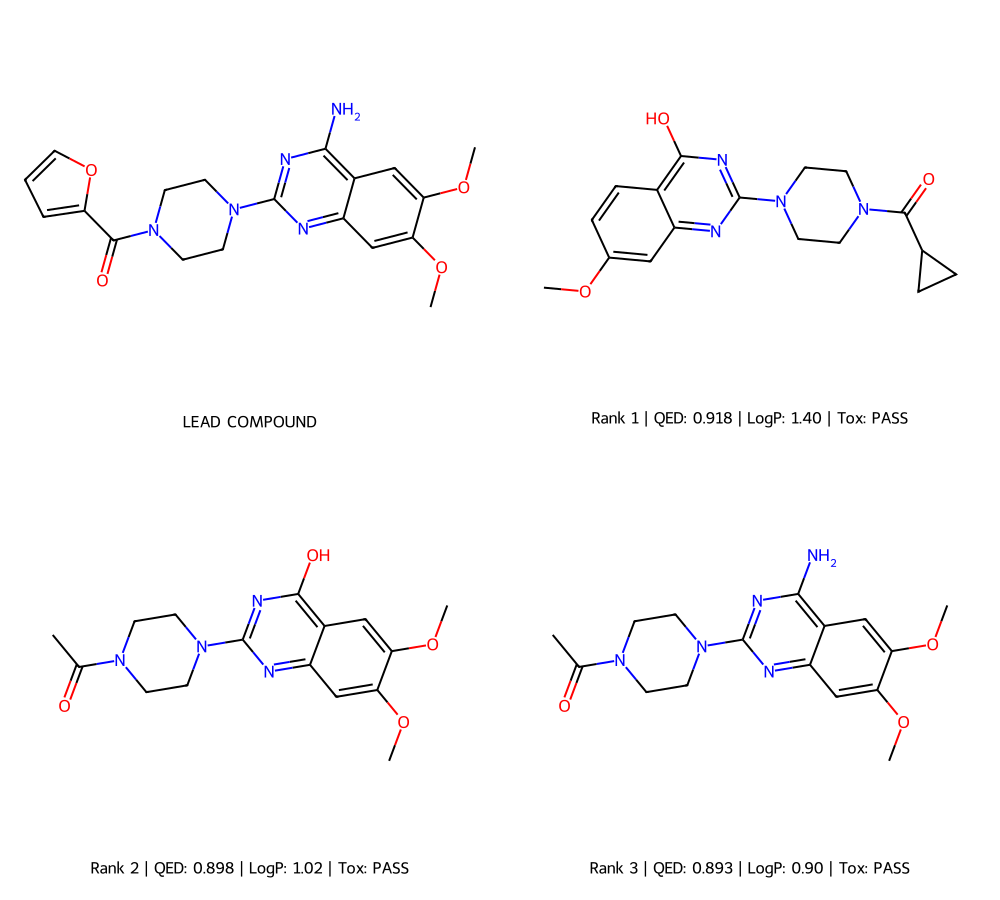

 Lead compound + top 3 analogs by QED score


In [38]:
print("=" * 60)
print("   2D MOLECULE STRUCTURES — PRAZOSIN ANALOGS")
print("=" * 60)
visualize_molecules(lead_smiles, scored)

##  Step 8: RDKit PAINS Toxicity Screening
Using RDKit's built-in PAINS filter, a hERG-risk heuristic (basic amine + logP + aromatic rings), and structural alert detection — industry-standard toxicity screening used in real pharmaceutical research.

In [39]:
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

def check_toxicity_pains(smiles):
    """
    Real toxicity screening using RDKit PAINS + structural alerts
    PAINS = Pan-Assay Interference Compounds
    Used in real pharmaceutical research to flag problematic molecules
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return {"PAINS": "❌ Invalid", "structural_alerts": "❌ Invalid", "overall": "❌ Invalid"}

    # PAINS filter — flags compounds that interfere with biological assays
    params = FilterCatalogParams()
    params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
    catalog = FilterCatalog(params)
    pains_hit = catalog.HasMatch(mol)

    # Structural alert checks via RDKit
    # hERG-risk heuristic: basic aliphatic amine + lipophilicity + aromatic rings (not a hERG model)
    herg_level, _, _ = herg_risk_heuristic(mol)
    herg_risk = (herg_level == "HIGH")

    # Reactive group alert — flags potentially toxic functional groups
    reactive_smarts = [
        "[N;!$(NC=O)][OH]",        # hydroxylamine
        "C(=O)[F,Cl,Br,I]",        # acid halide
        "[CH2][Cl,Br,I]",          # alkyl halide
        "N=[N+]=[N-]",             # azide
        "C1CO1",                   # epoxide
    ]
    reactive_flag = False
    for smarts in reactive_smarts:
        pattern = Chem.MolFromSmarts(smarts)
        if pattern and mol.HasSubstructMatch(pattern):
            reactive_flag = True
            break

    pains_flag =    "⚠️ PAINS alert"    if pains_hit    else "✅ No PAINS"
    herg_flag =     "⚠️ hERG-risk HIGH (heuristic)" if herg_risk else f"✅ hERG-risk {herg_level} (heuristic)"
    reactive =      "⚠️ Reactive group" if reactive_flag else "✅ No alerts"

    overall = "⚠️ WARN" if any([pains_hit, herg_risk, reactive_flag]) else "✅ PASS"

    return {
        "PAINS":             pains_flag,
        "hERG proxy":        herg_flag,
        "Structural alerts": reactive,
        "overall":           overall
    }

# Test on top candidate
print(" Testing RDKit PAINS toxicity filter...")
test_smiles = scored[0]['smiles']
result = check_toxicity_pains(test_smiles)
print(f"\nSMILES: {test_smiles[:45]}...")
print(f"PAINS:             {result['PAINS']}")
print(f"hERG proxy:        {result['hERG proxy']}")
print(f"Structural alerts: {result['Structural alerts']}")
print(f"Overall:           {result['overall']}")

 Testing RDKit PAINS toxicity filter...

SMILES: COc1ccc2c(O)nc(N3CCN(C(=O)C4CC4)CC3)nc2c1...
PAINS:             ✅ No PAINS
hERG proxy:        ✅ hERG-risk LOW (heuristic)
Structural alerts: ✅ No alerts
Overall:           ✅ PASS


POTENCY ESTIMATION

In [40]:
import re
import numpy as np
from collections import Counter
from chembl_webresource_client.new_client import new_client
from rdkit import Chem
from rdkit.DataStructs import BulkTanimotoSimilarity
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

_pot_gen = GetMorganGenerator(radius=2, fpSize=2048)

def build_potency_reference(lead_chembl_id, max_ref=3000):
    """Find the lead's most-measured human target, then collect known compounds + pChEMBL on it."""
    lead_acts = list(new_client.activity.filter(
        molecule_chembl_id=lead_chembl_id,
        pchembl_value__isnull=False,
        target_organism="Homo sapiens",
    ).only(["target_chembl_id", "target_pref_name", "pchembl_value"])[:500])
    if not lead_acts:
        print(f"No human pChEMBL data found for {lead_chembl_id}")
        return None

    target_id = Counter(a["target_chembl_id"] for a in lead_acts).most_common(1)[0][0]
    target_name = next(a["target_pref_name"] for a in lead_acts if a["target_chembl_id"] == target_id)
    lead_p = float(np.median([float(a["pchembl_value"]) for a in lead_acts
                              if a["target_chembl_id"] == target_id]))

    qs = new_client.activity.filter(
        target_chembl_id=target_id,
        pchembl_value__isnull=False,
        standard_relation="=",
    ).only(["canonical_smiles", "pchembl_value"])
    by_smiles = {}
    for a in qs[:max_ref]:
        smi = a.get("canonical_smiles")
        if smi:
            by_smiles.setdefault(smi, []).append(float(a["pchembl_value"]))

    fps, ps = [], []
    for smi, vals in by_smiles.items():
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            fps.append(_pot_gen.GetFingerprint(mol))
            ps.append(float(np.median(vals)))

    print(f"Potency reference: {target_name} ({target_id}) | {len(fps)} known compounds | "
          f"lead measured pChEMBL = {lead_p:.2f}")
    return {"target_id": target_id, "target_name": target_name,
            "lead_pchembl": lead_p, "fps": fps, "pchembl": np.array(ps)}


def estimate_potency(smiles, ref, k=5):
    """Similarity-weighted kNN estimate of pChEMBL. Returns (estimate, nearest_sim, confidence)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or ref is None:
        return None
    sims = np.array(BulkTanimotoSimilarity(_pot_gen.GetFingerprint(mol), ref["fps"]))
    top = np.argsort(sims)[::-1][:k]
    w = np.clip(sims[top], 1e-6, None)
    est = float(np.average(ref["pchembl"][top], weights=w))
    max_sim = float(sims[top[0]])
    conf = "HIGH" if max_sim >= 0.6 else "MEDIUM" if max_sim >= 0.4 else "LOW"
    return est, max_sim, conf


def add_potency(ref, candidates):
    """Adds est_pChEMBL, est_nM, potency_conf, nearest_active_sim, potency_text to each candidate."""
    for c in candidates:
        r = estimate_potency(c["smiles"], ref)
        if r is None:
            c.update(est_pChEMBL=None, est_nM=None, potency_conf="N/A",
                     nearest_active_sim=None, potency_text="n/a (no ChEMBL reference)")
            continue
        est, max_sim, conf = r
        nm = 10 ** (9 - est)
        c["est_pChEMBL"] = round(est, 2)
        c["est_nM"] = round(nm, 1)
        c["potency_conf"] = conf
        c["nearest_active_sim"] = round(max_sim, 2)
        c["potency_text"] = (f"pChEMBL~{est:.2f} (~{nm:.0f} nM, {est - ref['lead_pchembl']:+.2f} vs lead, "
                             f"confidence {conf}, nearest known compound Tanimoto {max_sim:.2f})")


def validate_potency_model(ref, n=300, k=5, seed=42):
    """Leave-one-out check so you can quote an error figure for the estimator."""
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(ref["fps"]), size=min(n, len(ref["fps"])), replace=False)
    true, pred = [], []
    for i in idx:
        sims = np.array(BulkTanimotoSimilarity(ref["fps"][i], ref["fps"]))
        sims[i] = -1
        top = np.argsort(sims)[::-1][:k]
        pred.append(np.average(ref["pchembl"][top], weights=np.clip(sims[top], 1e-6, None)))
        true.append(ref["pchembl"][i])
    true, pred = np.array(true), np.array(pred)
    print(f"Leave-one-out on {len(idx)} compounds: MAE = {np.mean(np.abs(true - pred)):.2f} pChEMBL units, "
          f"Pearson r = {np.corrcoef(true, pred)[0, 1]:.2f}")

In [41]:
# ============================================
# UPGRADED FULL PIPELINE WITH PAINS TOXICITY
# ============================================

lead_name = list(chembl_leads.keys())[0]
lead_smiles = list(chembl_leads.values())[0]

print("=" * 60)
print("   UPGRADED PIPELINE — ChEMBL + PAINS Toxicity")
print("=" * 60)
print(f"\n Lead: {lead_name}")

print("\n Step 1: Generating analogs via MolMIM...")
result = generate_analogs(lead_smiles, num_samples=10)
smiles_list = [item["sample"] for item in json.loads(result["molecules"]) if item["sample"] is not None]
print(f" {len(smiles_list)} analogs generated")

print("\n Step 2: RDKit scoring + PAINS toxicity check...")
scored = validate_and_score(smiles_list)

# Add PAINS toxicity to each candidate
for candidate in scored:
    tox = check_toxicity_pains(candidate['smiles'])
    candidate['PAINS']             = tox['PAINS']
    candidate['hERG']              = tox['hERG proxy']
    candidate['structural_alerts'] = tox['Structural alerts']
    candidate['tox_overall']       = tox['overall']

# Potency estimate (ChEMBL leads only)
lead_chembl_id = re.search(r"\((CHEMBL\d+)\)", lead_name).group(1)
potency_ref = build_potency_reference(lead_chembl_id)
if potency_ref:
    validate_potency_model(potency_ref)
add_potency(potency_ref, scored)
print(f" {len(scored)} candidates scored + toxicity checked")

# Show full table
import pandas as pd
df = pd.DataFrame(scored)
df.index = df.index + 1
print("\n FULL CANDIDATE TABLE:")
# Use display() for better rendering of DataFrames in Colab
display(df[['smiles', 'QED', 'logP', 'lipinski',
          'PAINS', 'hERG', 'structural_alerts',
          'tox_overall', 'synthesis','est_pChEMBL', 'potency_conf']])

print("\n Step 3: Ranking via Muse Glimmer...")
explanation = rank_with_llm_v2(lead_smiles, scored)

print("\n" + "=" * 60)
print("   FINAL RANKED OUTPUT WITH TOXICITY SCREENING")
print("=" * 60)
print(explanation)

   UPGRADED PIPELINE — ChEMBL + PAINS Toxicity

 Lead: PRAZOSIN (CHEMBL2)

 Step 1: Generating analogs via MolMIM...
 10 analogs generated

 Step 2: RDKit scoring + PAINS toxicity check...
Potency reference: Alpha-1A adrenergic receptor (CHEMBL229) | 2241 known compounds | lead measured pChEMBL = 9.23
Leave-one-out on 300 compounds: MAE = 0.67 pChEMBL units, Pearson r = 0.73
 10 candidates scored + toxicity checked

 FULL CANDIDATE TABLE:


,smiles,QED,logP,lipinski,PAINS,hERG,structural_alerts,tox_overall,synthesis,est_pChEMBL,potency_conf
1,COc1cc(N2CCN(C(=O)c3ccoc3)CC2)c(C#N)cc1O,0.925,1.83,✅ PASS,✅ No PAINS,✅ hERG-risk LOW (heuristic),✅ No alerts,✅ PASS,✅ Easy,7.67,LOW
2,COc1cc(N)nc(N2CCN(C(=O)c3ccco3)CC2)n1,0.887,0.62,✅ PASS,✅ No PAINS,✅ hERG-risk LOW (heuristic),✅ No alerts,✅ PASS,✅ Easy,8.00,HIGH
3,COc1cc(N)cc(N2CCN(C(=O)c3ccoc3)CC2)c1,0.876,1.83,✅ PASS,✅ No PAINS,✅ hERG-risk LOW (heuristic),✅ No alerts,✅ PASS,✅ Easy,7.83,LOW
4,COc1cc(N)c(N2CCN(C(=O)c3cccs3)CC2)cc1OC,0.860,2.31,✅ PASS,⚠️ PAINS alert,✅ hERG-risk LOW (heuristic),✅ No alerts,⚠️ WARN,✅ Easy,8.46,MEDIUM
5,Nc1cc2c(cc1N1CCN(C(=O)c3ccco3)CC1)OCO2,0.847,1.55,✅ PASS,⚠️ PAINS alert,✅ hERG-risk LOW (heuristic),✅ No alerts,⚠️ WARN,✅ Easy,7.92,MEDIUM
6,Cc1ccc(N)cc1S(=O)(=O)N1CCN(C(=O)c2ccco2)CC1,0.843,1.32,✅ PASS,✅ No PAINS,✅ hERG-risk LOW (heuristic),✅ No alerts,✅ PASS,✅ Easy,7.91,MEDIUM
7,COc1cc(OC)nc(N2CCN(C(=O)c3ccoc3)CC2)n1,0.833,1.05,✅ PASS,✅ No PAINS,✅ hERG-risk LOW (heuristic),✅ No alerts,✅ PASS,✅ Easy,8.50,MEDIUM
8,COc1c(N)nc(N2CCN(C(=O)c3ccoc3)CC2)nc1O,0.831,0.33,✅ PASS,✅ No PAINS,✅ hERG-risk LOW (heuristic),✅ No alerts,✅ PASS,✅ Easy,7.92,MEDIUM
9,NCc1cc(O)nc(CN2CCN(C(=O)c3ccco3)CC2)n1,0.828,0.19,✅ PASS,✅ No PAINS,✅ hERG-risk MODERATE (heuristic),✅ No alerts,✅ PASS,✅ Easy,8.31,MEDIUM
10,COc1ccc(N)c(S(=O)(=O)N2CCN(C(=O)c3ccco3)CC2)c1,0.811,1.02,✅ PASS,✅ No PAINS,✅ hERG-risk LOW (heuristic),✅ No alerts,✅ PASS,✅ Easy,8.31,MEDIUM



 Step 3: Ranking via Muse Glimmer...

   FINAL RANKED OUTPUT WITH TOXICITY SCREENING
**Lead:** dimethoxy-2-amino-quinazoline-piperazine-furoyl

Top 3 by QED > Safety PASS > SA low

### 1. Rank 1
**SMILES:** `COc1cc(N2CCN(C(=O)c3ccoc3)CC2)c(C#N)cc1O`
* **Why promising:** Highest drug-likeness QED 0.925, LogP 1.83, Lipinski PASS. Clean safety: PAINS No, hERG-risk LOW, Alerts No, Tox PASS. Synthesis Easy SA 2.44.
* **Concerns:** Phenol + nitrile on same ring. Phenol is a Phase II liability, nitrile can be a metabolic / chemical reactivity flag despite no structural alert. Monitor for oxidative metabolism and potential cyanide release.

### 2. Rank 2
**SMILES:** `COc1cc(N)nc(N2CCN(C(=O)c3ccco3)CC2)n1`
* **Why promising:** QED 0.887, second best drug-likeness. Clean safety profile: PAINS No, hERG-risk LOW, Alerts No, Tox PASS. Very easy synthesis SA 2.34.
* **Concerns:** LogP 0.62 is low for passive permeability. 2-amino-pyrimidine is electron rich and can be prone to oxidative metabolism 

   2D MOLECULE STRUCTURES — UPGRADED PIPELINE


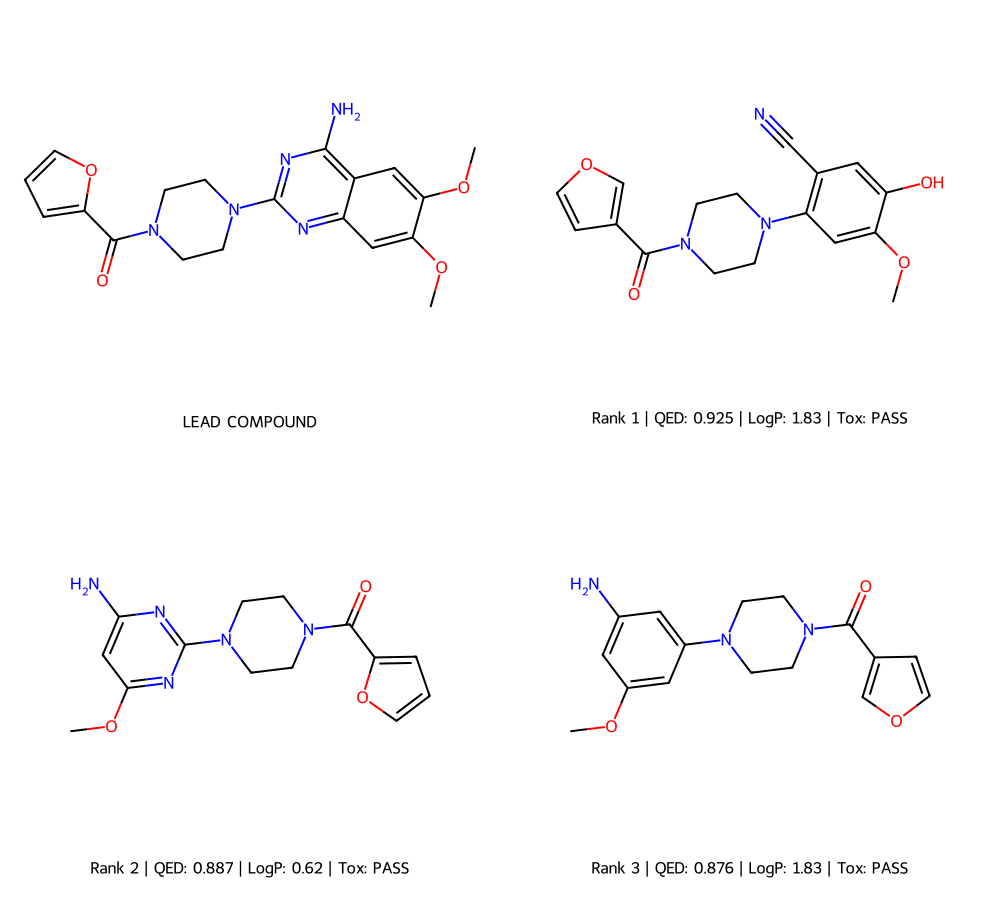

 Lead compound + top 3 analogs by QED score


In [42]:
print("=" * 60)
print("   2D MOLECULE STRUCTURES — UPGRADED PIPELINE")
print("=" * 60)
visualize_molecules(lead_smiles, scored)

EVALUATION METRICS

In [43]:
from rdkit.DataStructs import TanimotoSimilarity
from rdkit.Chem import AllChem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

def _is_pass(v):
    """True for '✅ PASS'-style labels or a plain True."""
    return v is True or 'PASS' in str(v)
def evaluate_pipeline(lead_smiles, scored_candidates, potency_ref=None):
    print("=" * 60)
    print("   PIPELINE EVALUATION METRICS")
    print("=" * 60)

    lead_mol = Chem.MolFromSmiles(lead_smiles)
    lead_qed = QED.qed(lead_mol)

    # Initialize MorganGenerator
    morgan_gen = GetMorganGenerator(radius=2, fpSize=1024)
    lead_fp = morgan_gen.GetFingerprint(lead_mol)

    # 1. QED improvement
    analog_qeds = [c['QED'] for c in scored_candidates]
    avg_qed = sum(analog_qeds) / len(analog_qeds)
    best_qed = max(analog_qeds)
    improvement = ((best_qed - lead_qed) / lead_qed) * 100

    print(f"\n QED SCORES:")
    print(f"   Lead compound QED  : {lead_qed:.3f}")
    print(f"   Average analog QED : {avg_qed:.3f}")
    print(f"   Best analog QED    : {best_qed:.3f}")
    print(f"   QED improvement    : +{improvement:.1f}% over lead")

    # 2. Tanimoto similarity — diversity check
    similarities = []
    for c in scored_candidates:
        mol = Chem.MolFromSmiles(c['smiles'])
        if mol:
            fp = morgan_gen.GetFingerprint(mol)
            sim = TanimotoSimilarity(lead_fp, fp)
            similarities.append(sim)

    avg_sim = sum(similarities) / len(similarities)
    print(f"\n DIVERSITY (Tanimoto Similarity to Lead):")
    print(f"   Average similarity : {avg_sim:.3f}")
    print(f"   (0 = completely different, 1 = identical)")
    print(f"   Interpretation     : {'Good diversity' if avg_sim < 0.7 else 'Low diversity — analogs too similar'}")

    # 3. Filter pass rates
    lipinski_pass = sum(1 for c in scored_candidates if _is_pass(c['lipinski']))
    tox_pass = sum(1 for c in scored_candidates if _is_pass(c.get('tox_overall', c.get('toxicity', ''))))
    pains_pass = sum(1 for c in scored_candidates if 'No PAINS' in str(c.get('PAINS', '')))

    print(f"\n FILTER PASS RATES (out of {len(scored_candidates)} analogs):")
    print(f"   Lipinski rules     : {lipinski_pass}/{len(scored_candidates)} passed ({lipinski_pass/len(scored_candidates)*100:.0f}%)")
    print(f"   Toxicity overall   : {tox_pass}/{len(scored_candidates)} passed ({tox_pass/len(scored_candidates)*100:.0f}%)")
    if any('PAINS' in c for c in scored_candidates):
        print(f"   PAINS filter       : {pains_pass}/{len(scored_candidates)} passed ({pains_pass/len(scored_candidates)*100:.0f}%)")

    # 4. Synthesis feasibility
    easy = sum(1 for c in scored_candidates if 'Easy' in str(c['synthesis']))
    moderate = sum(1 for c in scored_candidates if 'Moderate' in str(c['synthesis']))
    complex_ = sum(1 for c in scored_candidates if 'Complex' in str(c['synthesis']))

    print(f"\n SYNTHESIS FEASIBILITY:")
    print(f"   Easy      : {easy}/{len(scored_candidates)}")
    print(f"   Moderate  : {moderate}/{len(scored_candidates)}")
    print(f"   Complex   : {complex_}/{len(scored_candidates)}")

    # 5. hERG-risk heuristic + SA score
    herg_high = sum(1 for c in scored_candidates if 'HIGH' in str(c.get('hERG', '')))
    sa_vals = [c['SA_score'] for c in scored_candidates if 'SA_score' in c]
    print(f"\n HERG-RISK HEURISTIC + SA SCORE:")
    print(f"   hERG-risk HIGH (heuristic) : {herg_high}/{len(scored_candidates)}")
    if sa_vals:
        print(f"   Mean SA score (1 easy - 10 hard): {sum(sa_vals)/len(sa_vals):.2f}")

        # 6. Potency estimate (ligand-based, from ChEMBL)
    pot = [c for c in scored_candidates if c.get('est_pChEMBL') is not None]
    if pot and potency_ref:
        best = max(pot, key=lambda c: c['est_pChEMBL'])
        n_conf = sum(1 for c in pot if c['potency_conf'] in ('MEDIUM', 'HIGH'))
        n_ge_lead = sum(1 for c in pot if c['est_pChEMBL'] >= potency_ref['lead_pchembl'])
        print(f"\n POTENCY ESTIMATE (ligand-based, target: {potency_ref['target_name']}):")
        print(f"   Lead measured pChEMBL               : {potency_ref['lead_pchembl']:.2f}")
        print(f"   Best analog estimate                : {best['est_pChEMBL']:.2f} (confidence {best['potency_conf']})")
        print(f"   Analogs with MEDIUM/HIGH confidence : {n_conf}/{len(pot)}")
        print(f"   Analogs estimated >= lead potency   : {n_ge_lead}/{len(pot)}")

    print(f"\n SUMMARY:")
    print(f"   Best analog is {improvement:.1f}% more drug-like than lead compound")
    print(f"   {tox_pass}/{len(scored_candidates)} analogs passed all toxicity screening filters")
    print(f"   Average structural diversity from lead: {avg_sim:.3f} Tanimoto")
    print("=" * 60)

evaluate_pipeline(lead_smiles, scored, potency_ref)

   PIPELINE EVALUATION METRICS

 QED SCORES:
   Lead compound QED  : 0.727
   Average analog QED : 0.854
   Best analog QED    : 0.925
   QED improvement    : +27.3% over lead

 DIVERSITY (Tanimoto Similarity to Lead):
   Average similarity : 0.436
   (0 = completely different, 1 = identical)
   Interpretation     : Good diversity

 FILTER PASS RATES (out of 10 analogs):
   Lipinski rules     : 10/10 passed (100%)
   Toxicity overall   : 8/10 passed (80%)
   PAINS filter       : 8/10 passed (80%)

 SYNTHESIS FEASIBILITY:
   Easy      : 10/10
   Moderate  : 0/10
   Complex   : 0/10

 HERG-RISK HEURISTIC + SA SCORE:
   hERG-risk HIGH (heuristic) : 0/10
   Mean SA score (1 easy - 10 hard): 2.33

 POTENCY ESTIMATE (ligand-based, target: Alpha-1A adrenergic receptor):
   Lead measured pChEMBL               : 9.23
   Best analog estimate                : 8.50 (confidence MEDIUM)
   Analogs with MEDIUM/HIGH confidence : 8/10
   Analogs estimated >= lead potency   : 0/10

 SUMMARY:
   Best ana

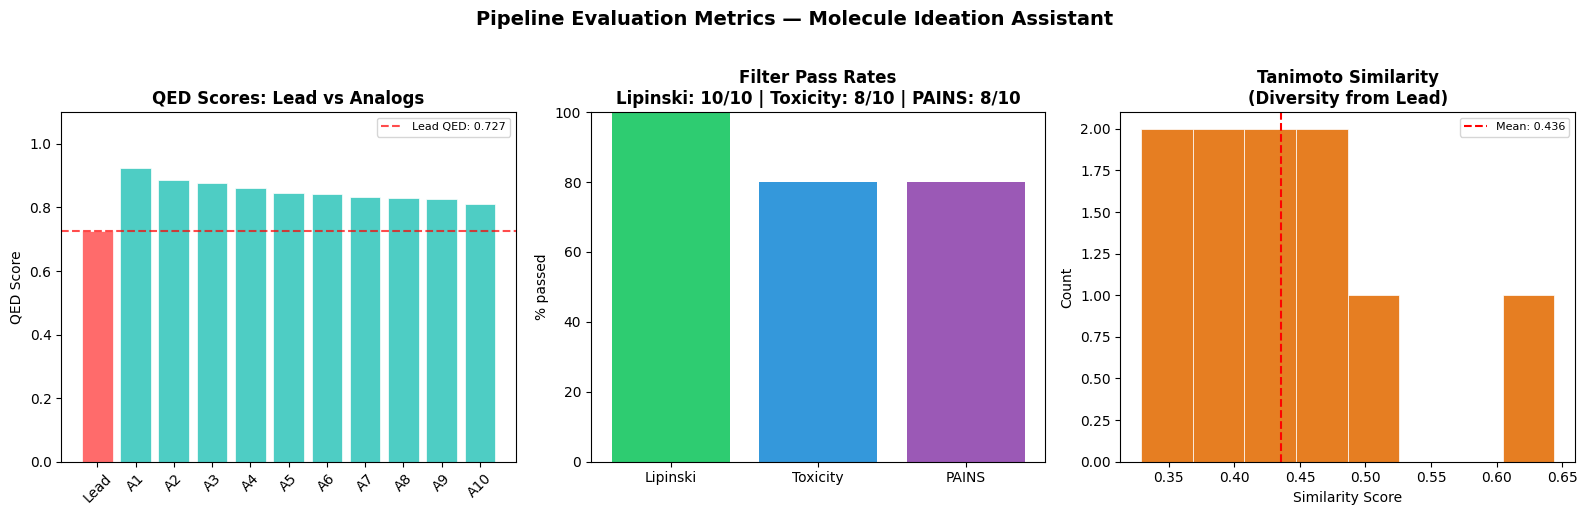

 Evaluation charts generated!


In [44]:
import matplotlib.pyplot as plt
import numpy as np
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

def _is_pass(v):
    """True for '✅ PASS'-style labels or a plain True."""
    return v is True or 'PASS' in str(v)

def plot_evaluation(lead_smiles, scored_candidates):
    lead_mol = Chem.MolFromSmiles(lead_smiles)
    lead_qed = QED.qed(lead_mol)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle('Pipeline Evaluation Metrics — Molecule Ideation Assistant',
                 fontsize=14, fontweight='bold', y=1.02)

    # ── Plot 1: QED comparison bar chart
    analog_qeds = [c['QED'] for c in scored_candidates]
    x = ['Lead'] + [f"A{i+1}" for i in range(len(analog_qeds))]
    y = [lead_qed] + analog_qeds
    colors = ['#FF6B6B'] + ['#4ECDC4' if q > lead_qed else '#95A5A6' for q in analog_qeds]

    axes[0].bar(x, y, color=colors, edgecolor='white', linewidth=0.5)
    axes[0].axhline(y=lead_qed, color='red', linestyle='--', alpha=0.7, label=f'Lead QED: {lead_qed:.3f}')
    axes[0].set_title('QED Scores: Lead vs Analogs', fontweight='bold')
    axes[0].set_ylabel('QED Score')
    axes[0].set_ylim(0, 1.1)
    axes[0].legend(fontsize=8)
    axes[0].tick_params(axis='x', rotation=45)

    # ── Plot 2: Filter pass rates donut
    n_total = len(scored_candidates)
    labels = ['Lipinski', 'Toxicity', 'PAINS']
    passed = [
        sum(1 for c in scored_candidates if _is_pass(c['lipinski'])),
        sum(1 for c in scored_candidates if _is_pass(c.get('tox_overall', c.get('toxicity', '')))),
        sum(1 for c in scored_candidates if 'No PAINS' in str(c.get('PAINS', ''))),
    ]
    sizes = [p / n_total * 100 for p in passed]  # computed pass rates (%)
    colors2 = ['#2ECC71', '#3498DB', '#9B59B6']
    axes[1].bar(labels, sizes, color=colors2)
    axes[1].set_ylim(0, 100)
    axes[1].set_ylabel('% passed')
    axes[1].set_title('Filter Pass Rates\n' + ' | '.join(f'{l}: {p}/{n_total}' for l, p in zip(labels, passed)), fontweight='bold')

    # ── Plot 3: Tanimoto similarity distribution
    from rdkit.DataStructs import TanimotoSimilarity
    from rdkit.Chem import AllChem

    morgan_gen = GetMorganGenerator(radius=2, fpSize=1024)
    lead_fp = morgan_gen.GetFingerprint(lead_mol)
    sims = []
    for c in scored_candidates:
        mol = Chem.MolFromSmiles(c['smiles'])
        if mol:
            fp = morgan_gen.GetFingerprint(mol)
            sims.append(TanimotoSimilarity(lead_fp, fp))

    axes[2].hist(sims, bins=8, color='#E67E22', edgecolor='white', linewidth=0.5)
    axes[2].axvline(x=np.mean(sims), color='red', linestyle='--', label=f'Mean: {np.mean(sims):.3f}')
    axes[2].set_title('Tanimoto Similarity\n(Diversity from Lead)', fontweight='bold')
    axes[2].set_xlabel('Similarity Score')
    axes[2].set_ylabel('Count')
    axes[2].legend(fontsize=8)

    plt.tight_layout()
    plt.show()
    print(" Evaluation charts generated!")

# Run
plot_evaluation(lead_smiles, scored)

LANGRAPH

INSTALLATION

In [45]:
!pip install -q langgraph langgraph-checkpoint

In [56]:
_POTENCY_REGISTRY = {}   # module-level, never checkpointed

def to_state_safe(ref):
    """Stash the full reference (fps + ndarray) and return a serializable stub."""
    if ref is None:
        return None
    _POTENCY_REGISTRY[ref["target_id"]] = ref
    return {
        "target_id": ref["target_id"],
        "target_name": ref["target_name"],
        "lead_pchembl": float(ref["lead_pchembl"]),
    }

potency_ref_state = to_state_safe(potency_ref)

THE STATE


In [57]:
from typing import TypedDict, List, Dict, Optional, Literal
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

class MoleculeState(TypedDict):
    lead_name: str
    lead_smiles: str
    smiles_list: List[str]        # raw SMILES from the current MolMIM round
    candidates: List[Dict]        # fully scored (RDKit + PAINS/hERG + potency)
    feedback: str                 # why the last round failed, used to steer regeneration
    iteration: int
    max_iterations: int
    pass_threshold: float         # e.g. 0.5 = at least half must clear every filter
    potency_ref: Optional[Dict]   # from build_potency_reference(), or None
    approved: bool
    human_notes: str
    final_ranking: str
    round_history: List[Dict]     # per-iteration stats, used later for the eval

GENERATE NODE

In [58]:
import json

def generate_node(state: MoleculeState) -> dict:
    iteration = state["iteration"]
    if iteration == 0:
        seed = state["lead_smiles"]
        print(f"\n=== ITERATION {iteration + 1}: GENERATE (seed = lead compound) ===")
    else:
        prev = state["candidates"]
        # Reseed from whichever prior candidate scored best, rather than the original lead —
        # this IS the regeneration step, since MolMIM has no text-feedback input.
        seed = max(prev, key=lambda c: c["QED"])["smiles"] if prev else state["lead_smiles"]
        print(f"\n=== ITERATION {iteration + 1}: REGENERATE (seed = best prior analog) ===")
        print(f"    Feedback from last round: {state['feedback']}")

    result = generate_analogs(seed, num_samples=10)
    raw_smiles = [item["sample"] for item in json.loads(result["molecules"]) if item["sample"]]
    smiles_list = dedupe_smiles(raw_smiles)
    print(f"    {len(smiles_list)} unique candidate(s) generated")

    return {"smiles_list": smiles_list, "iteration": iteration + 1}

Validate node

In [66]:
def validate_node(state: MoleculeState) -> dict:
    print("--- VALIDATE: RDKit scoring + PAINS/hERG + potency ---")
    scored = validate_and_score(state["smiles_list"])

    for c in scored:
        tox = check_toxicity_pains(c["smiles"])
        c["PAINS"] = tox["PAINS"]
        c["hERG"] = tox["hERG proxy"]
        c["structural_alerts"] = tox["Structural alerts"]
        c["tox_overall"] = tox["overall"]
    stub = state.get("potency_ref")
    if stub:
        ref = _POTENCY_REGISTRY[stub["target_id"]]   # full ref: fps + pchembl
        add_potency(ref, scored)

    n = len(scored)
    n_all_pass = sum(
        1 for c in scored
        if "PASS" in c["lipinski"] and "No PAINS" in c["PAINS"] and "PASS" in c["tox_overall"]
    )
    pass_rate = n_all_pass / n if n else 0.0
    print(f"    {n_all_pass}/{n} candidates passed ALL filters ({pass_rate:.0%})")

    return {
        "candidates": scored,
        "round_history": state["round_history"] + [{
            "iteration": state["iteration"], "n": n, "pass_rate": pass_rate,
        }],
    }

Diagnose node + routing function

In [67]:
def diagnose_node(state: MoleculeState) -> dict:
    scored = state["candidates"]
    n = len(scored)
    fails = {
        "Lipinski":         sum(1 for c in scored if "FAIL" in c["lipinski"]),
        "PAINS":            sum(1 for c in scored if "PAINS alert" in c["PAINS"]),
        "hERG-risk HIGH":   sum(1 for c in scored if "HIGH" in c["hERG"]),
        "Structural alert": sum(1 for c in scored if "Reactive group" in c["structural_alerts"]),
    }
    worst = max(fails, key=fails.get)
    feedback = (
        f"{fails[worst]}/{n} analogs failed {worst}; reseeding from best-QED survivor."
        if fails[worst] else "All filters clear."
    )
    return {"feedback": feedback}

def route_after_diagnose(state: MoleculeState) -> Literal["regenerate", "human_review"]:
    latest = state["round_history"][-1]
    if latest["pass_rate"] < state["pass_threshold"] and state["iteration"] < state["max_iterations"]:
        return "regenerate"
    return "human_review"

Human-in-the-loop node

In [68]:
def human_review_node(state: MoleculeState) -> dict:
    decision = interrupt({
        "message": "Review validated candidates before final ranking.",
        "lead": state["lead_name"],
        "iteration": state["iteration"],
        "pass_rate": state["round_history"][-1]["pass_rate"],
        "candidates": [
            {"smiles": c["smiles"], "QED": c["QED"], "lipinski": c["lipinski"],
             "PAINS": c["PAINS"], "hERG": c["hERG"]}
            for c in state["candidates"]
        ],
    })
    return {"approved": decision.get("approved", True), "human_notes": decision.get("notes", "")}

def route_after_human(state: MoleculeState) -> Literal["rank", "regenerate"]:
    return "rank" if state["approved"] else "regenerate"

Rank node

In [69]:
def rank_node(state: MoleculeState) -> dict:
    print("--- RANK: LLM explains + ranks top 3 ---")
    explanation = rank_with_llm_v2(state["lead_smiles"], state["candidates"])
    return {"final_ranking": explanation}

Wire the graph together

In [70]:
graph = StateGraph(MoleculeState)

graph.add_node("generate", generate_node)
graph.add_node("validate", validate_node)
graph.add_node("diagnose", diagnose_node)
graph.add_node("human_review", human_review_node)
graph.add_node("rank", rank_node)

graph.set_entry_point("generate")
graph.add_edge("generate", "validate")
graph.add_edge("validate", "diagnose")

# Conditional edge: diagnose_node's output decides where to go next
graph.add_conditional_edges("diagnose", route_after_diagnose, {
    "regenerate": "generate",
    "human_review": "human_review",
})
graph.add_conditional_edges("human_review", route_after_human, {
    "rank": "rank",
    "regenerate": "generate",
})
graph.add_edge("rank", END)

checkpointer = MemorySaver()   # remembers state across the interrupt/resume pause
app = graph.compile(checkpointer=checkpointer)

In [71]:
lead_name = list(chembl_leads.keys())[0]
lead_smiles = list(chembl_leads.values())[0]

config = {"configurable": {"thread_id": f"{lead_name}-run-1"}}  # identifies this paused run

initial_state = {
    "lead_name": lead_name, "lead_smiles": lead_smiles,
    "smiles_list": [], "candidates": [], "feedback": "",
    "iteration": 0, "max_iterations": 4, "pass_threshold": 0.5,
    "potency_ref": potency_ref_state, "approved": False, "human_notes": "",
    "final_ranking": "", "round_history": [],
}

result = app.invoke(initial_state, config=config)

if "__interrupt__" in result:
    payload = result["__interrupt__"][0].value
    print(f"\n{payload['message']} (pass rate: {payload['pass_rate']:.0%})")
    for c in payload["candidates"]:
        print(f"  {c['smiles'][:50]}  QED={c['QED']}  {c['lipinski']}  {c['PAINS']}")

    # --- in a real app this comes from your UI; here, simulate approval ---
    result = app.invoke(Command(resume={"approved": True, "notes": "Looks good"}), config=config)

print("\n" + "=" * 60)
print(result["final_ranking"])


=== ITERATION 1: GENERATE (seed = lead compound) ===
   removed 6 duplicate/invalid analog(s)
    4 unique candidate(s) generated
--- VALIDATE: RDKit scoring + PAINS/hERG + potency ---
    4/4 candidates passed ALL filters (100%)

Review validated candidates before final ranking. (pass rate: 100%)
  COc1cnc(N2CCN(/C=C/c3ccccc3)CC2)nc1N  QED=0.929  ✅ PASS  ✅ No PAINS
  CC(C)(C)Oc1cnc(N2CCN(Cc3ccccc3)CC2)nc1N  QED=0.922  ✅ PASS  ✅ No PAINS
  COc1cc(N)nc(N2CCN(Cc3ccccc3)CC2)n1  QED=0.92  ✅ PASS  ✅ No PAINS
  COc1cnc(N2CCN(Cc3ccccc3)CC2)nc1N  QED=0.92  ✅ PASS  ✅ No PAINS
--- RANK: LLM explains + ranks top 3 ---

**Top 3 ranked by QED > Safety PASS > SA lower = easier**

All 4 analogs are PAINS negative, no structural alerts, Tox Overall PASS, Lipinski PASS and hERG-risk MODERATE heuristic. Ranking is driven by QED then synthetic accessibility.

### 1. Rank 1
**SMILES:** `COc1cnc(N2CCN(/C=C/c3ccccc3)CC2)nc1N`
* QED 0.929 | LogP 1.86 | SA 2.52

**Why promising:** Highest drug-likeness of th

Eval: agent loop vs. one-shot

In [72]:
import pandas as pd
from rdkit.DataStructs import TanimotoSimilarity
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

def run_one_shot(lead_smiles, potency_ref=None):
    result = generate_analogs(lead_smiles, num_samples=10)
    smiles_list = dedupe_smiles([item["sample"] for item in json.loads(result["molecules"]) if item["sample"]])
    scored = validate_and_score(smiles_list)
    for c in scored:
        tox = check_toxicity_pains(c["smiles"])
        c.update(PAINS=tox["PAINS"], hERG=tox["hERG proxy"], tox_overall=tox["overall"])
    if potency_ref:
        add_potency(potency_ref, scored)
    return scored

def run_agent_loop(name, smiles, potency_ref=None):
    config = {"configurable": {"thread_id": f"{name}-eval"}}
    state = {
        "lead_name": name, "lead_smiles": smiles, "smiles_list": [], "candidates": [],
        "feedback": "", "iteration": 0, "max_iterations": 4, "pass_threshold": 0.5,
        "potency_ref": potency_ref, "approved": False, "human_notes": "",
        "final_ranking": "", "round_history": [],
    }
    result = app.invoke(state, config=config)
    if "__interrupt__" in result:
        result = app.invoke(Command(resume={"approved": True, "notes": "auto-approved for eval"}), config=config)
    return result["candidates"]

def score_metrics(lead_smiles, scored):
    lead_mol = Chem.MolFromSmiles(lead_smiles)
    lead_qed = QED.qed(lead_mol)
    gen = GetMorganGenerator(radius=2, fpSize=1024)
    lead_fp = gen.GetFingerprint(lead_mol)
    qeds = [c["QED"] for c in scored]
    sims = [TanimotoSimilarity(lead_fp, gen.GetFingerprint(Chem.MolFromSmiles(c["smiles"]))) for c in scored]
    n_pass = sum(1 for c in scored if "PASS" in c["lipinski"] and "No PAINS" in c["PAINS"] and "PASS" in c["tox_overall"])
    return {
        "n_candidates": len(scored),
        "pass_rate": n_pass / len(scored) if scored else 0,
        "best_qed": max(qeds) if qeds else 0,
        "qed_gain_pct": ((max(qeds) - lead_qed) / lead_qed * 100) if qeds else 0,
        "avg_diversity": 1 - (sum(sims) / len(sims) if sims else 0),
    }

def compare_pipelines(test_leads, refs=None):
    rows = []
    for name, smi in test_leads.items():
        ref = (refs or {}).get(name)
        rows.append({"lead": name, "pipeline": "one-shot", **score_metrics(smi, run_one_shot(smi, ref))})
        rows.append({"lead": name, "pipeline": "agent-loop", **score_metrics(smi, run_agent_loop(name, smi, ref))})
    return pd.DataFrame(rows)

comparison_df = compare_pipelines(chembl_leads)
comparison_df

   removed 1 duplicate/invalid analog(s)

=== ITERATION 1: GENERATE (seed = lead compound) ===
   removed 1 duplicate/invalid analog(s)
    9 unique candidate(s) generated
--- VALIDATE: RDKit scoring + PAINS/hERG + potency ---
    9/9 candidates passed ALL filters (100%)
--- RANK: LLM explains + ranks top 3 ---
   removed 1 duplicate/invalid analog(s)

=== ITERATION 1: GENERATE (seed = lead compound) ===
    10 unique candidate(s) generated
--- VALIDATE: RDKit scoring + PAINS/hERG + potency ---
    9/10 candidates passed ALL filters (90%)
--- RANK: LLM explains + ranks top 3 ---

=== ITERATION 1: GENERATE (seed = lead compound) ===
   removed 1 duplicate/invalid analog(s)
    9 unique candidate(s) generated
--- VALIDATE: RDKit scoring + PAINS/hERG + potency ---
    9/9 candidates passed ALL filters (100%)
--- RANK: LLM explains + ranks top 3 ---

=== ITERATION 1: GENERATE (seed = lead compound) ===
    10 unique candidate(s) generated
--- VALIDATE: RDKit scoring + PAINS/hERG + potency 

,lead,pipeline,n_candidates,pass_rate,best_qed,qed_gain_pct,avg_diversity
0,PRAZOSIN (CHEMBL2),one-shot,9,1.0,0.936,28.825863,0.551537
1,PRAZOSIN (CHEMBL2),agent-loop,9,1.0,0.914,25.797905,0.511351
2,NICOTINE (CHEMBL3),one-shot,9,1.0,0.918,46.609810,0.619134
3,NICOTINE (CHEMBL3),agent-loop,10,0.9,0.871,39.103644,0.588496
4,OFLOXACIN (CHEMBL4),one-shot,10,0.7,0.937,7.117565,0.668511
5,OFLOXACIN (CHEMBL4),agent-loop,9,1.0,0.924,5.631409,0.634716
6,NALIDIXIC ACID (CHEMBL5),one-shot,10,1.0,0.929,9.355396,0.621846
7,NALIDIXIC ACID (CHEMBL5),agent-loop,10,1.0,0.925,8.884544,0.591740
8,INDOMETHACIN (CHEMBL6),one-shot,10,1.0,0.936,21.905713,0.652394
9,INDOMETHACIN (CHEMBL6),agent-loop,10,0.7,0.941,22.556918,0.610288
